# 04 — Phân tích khám phá & trực quan hóa churn khách hàng Cell2Cell

**Vai trò:** chuyên viên phân tích dữ liệu của công ty viễn thông Cell2Cell.

**Bài toán kinh doanh:** mỗi tháng gần 3 trong 10 khách rời bỏ dịch vụ. Ban giám đốc cần biết:

1. Churn lớn đến đâu và gây thiệt hại bao nhiêu?
2. Tín hiệu nào (vòng đời, thiết bị, hành vi dịch vụ, địa lý, nhân khẩu) đi cùng churn?
3. Ai đang có nguy cơ rời bỏ và nên ưu tiên giữ ai?
4. Nên thử chính sách giữ chân nào?

**Cách chạy:** chạy `python work/viz/prepare_viz_data.py` trước (tạo `work/build/viz_customers.parquet`), sau đó Restart Kernel → Run All.
Mọi biểu đồ được vẽ bằng hàm trong `work/viz/charts.py`, cùng thư viện với dashboard, nên số liệu trên notebook và dashboard luôn khớp.
Tiêu đề mỗi biểu đồ là một **câu kết luận** sinh tự động từ số liệu.

## 1. Thiết lập

In [1]:
from pathlib import Path
import sys

import pandas as pd
import plotly.io as pio

# Tìm root dự án từ thư mục làm việc (chạy được từ root hoặc từ work/viz).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "cell2celltrain.csv").exists())
sys.path.insert(0, str(ROOT / "work" / "viz"))
import charts as c

# Hiển thị tương tác trong Jupyter/VS Code, kèm ảnh PNG để xem được trên GitHub.
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 1000
pio.renderers["png"].height = None

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)

def show(key):
    """Vẽ biểu đồ theo mã trong charts.FIGURES và lưu PNG vào reports/figures."""
    fig = c.FIGURES[key](df)
    fig.write_image(FIG_DIR / f"{key}.png", width=1000, scale=1.5)
    fig.show()

## 2. Tổng quan dữ liệu

Nguồn: `data/cell2celltrain.csv`, mỗi dòng là một khách hàng tại một thời điểm quan sát (snapshot), gồm 58 cột.
Biến mục tiêu `Churn` = Yes/No.

In [2]:
raw = pd.read_csv(ROOT / "data" / "cell2celltrain.csv", na_values=["NA"])
print(f"Raw: {c.fmt_n(raw.shape[0])} dòng × {raw.shape[1]} cột · CustomerID trùng: {raw.CustomerID.duplicated().sum()}")
print(raw.dtypes.value_counts().to_string())
raw.head()

Raw: 51.047 dòng × 58 cột · CustomerID trùng: 0
float64    26
object     23
int64       9


,CustomerID,Churn,MonthlyRevenue,MonthlyMinutes,TotalRecurringCharge,DirectorAssistedCalls,OverageMinutes,RoamingCalls,PercChangeMinutes,PercChangeRevenues,...,ReferralsMadeBySubscriber,IncomeGroup,OwnsMotorcycle,AdjustmentsToCreditRating,HandsetPrice,MadeCallToRetentionTeam,CreditRating,PrizmCode,Occupation,MaritalStatus
0,3000002,Yes,24.00,219.0,22.0,0.25,0.0,0.0,-157.0,-19.0,...,0,4,No,0,30,Yes,1-Highest,Suburban,Professional,No
1,3000010,Yes,16.99,10.0,17.0,0.00,0.0,0.0,-4.0,0.0,...,0,5,No,0,30,No,4-Medium,Suburban,Professional,Yes
2,3000014,No,38.00,8.0,38.0,0.00,0.0,0.0,-2.0,0.0,...,0,6,No,0,Unknown,No,3-Good,Town,Crafts,Yes
3,3000022,No,82.28,1312.0,75.0,1.24,0.0,0.0,157.0,8.1,...,0,6,No,0,10,No,4-Medium,Other,Other,No
4,3000026,Yes,17.14,0.0,17.0,0.00,0.0,0.0,0.0,-0.2,...,0,9,No,1,10,No,1-Highest,Other,Professional,Yes


In [3]:
raw.describe().T[["count", "mean", "50%", "min", "max"]].round(1).head(25)

,count,mean,50%,min,max
CustomerID,51047.0,3201956.9,3201534.0,3000002.0,3399994.0
MonthlyRevenue,50891.0,58.8,48.5,-6.2,1223.4
MonthlyMinutes,50891.0,525.7,366.0,0.0,7359.0
TotalRecurringCharge,50891.0,46.8,45.0,-11.0,400.0
DirectorAssistedCalls,50891.0,0.9,0.2,0.0,159.4
OverageMinutes,50891.0,40.0,3.0,0.0,4321.0
RoamingCalls,50891.0,1.2,0.0,0.0,1112.4
PercChangeMinutes,50680.0,-11.5,-5.0,-3875.0,5192.0
PercChangeRevenues,50680.0,-1.2,-0.3,-1107.7,2483.5
DroppedCalls,51047.0,6.0,3.0,0.0,221.7


## 3. Xử lý dữ liệu

Các bước trong `work/viz/prepare_viz_data.py` (không sửa file raw):

| Bước | Xử lý | Lý do |
|---|---|---|
| Missing | Chuỗi `NA` → giá trị thiếu. Numeric giữ NaN; categorical → `Unknown` | Missing rất ít (≤ 1,8%/cột), xóa dòng sẽ làm sai mẫu số |
| Target | `Churn` Yes/No → `ChurnFlag` 1/0; dừng nếu có giá trị lạ | Tính churn rate = trung bình `ChurnFlag` |
| Vùng | `Region` = 3 ký tự đầu `ServiceArea` (VD `NYC`, `LAX`) | 700+ mã vùng chi tiết quá nhỏ để so sánh |
| Band | Chia nhóm tenure, tuổi máy, cuộc gọi CSKH, cuộc gọi rớt, vượt gói, phút gọi; ngưỡng công khai | So sánh churn rate giữa các nhóm có nghĩa kinh doanh |
| Giá trị âm | `CurrentEquipmentDays` < 0 (76 khách) → nhóm `Bất thường`, không xóa | Có thể là lỗi nhập liệu; giữ để minh bạch |
| Outlier | Giữ nguyên; chỉ cắt 1% lớn nhất khi vẽ histogram cho dễ nhìn | Không có quy tắc nghiệp vụ để loại |
| Phân khúc | `ActionSegment` theo rule ưu tiên (mục 9) | Đầu vào cho chính sách giữ chân |
| Điểm rủi ro | Ghép `RiskScore`, `RiskDecile` từ notebook 03 (CatBoost, dự đoán ngoài mẫu) | Dùng lại kết quả có sẵn, không train lại |

In [4]:
df = pd.read_parquet(ROOT / "work" / "build" / "viz_customers.parquet")
k = c.kpis(df)
print(f"Bảng phân tích: {c.fmt_n(len(df))} khách · {c.fmt_n(k['churners'])} churn · churn rate {c.fmt_pct(k['rate'], 2)}")
print("Có điểm rủi ro:", "RiskDecile" in df)
df[["TenureBand", "EquipmentAgeBand", "CareCallsBand", "DroppedBand", "OverageBand", "MinutesBand", "ActionSegment"]].describe()

Bảng phân tích: 51.047 khách · 14.711 churn · churn rate 28,82%
Có điểm rủi ro: True


,TenureBand,EquipmentAgeBand,CareCallsBand,DroppedBand,OverageBand,MinutesBand,ActionSegment
count,51047,51047,51047,51047,51047,51047,51047
unique,6,6,5,5,5,4,5
top,7–12 tháng,181–365 ngày,0,≤5,0,>500 phút,Ổn định
freq,16229,19084,28020,18894,23262,19452,26425


### C02 — Dữ liệu thiếu ở đâu?

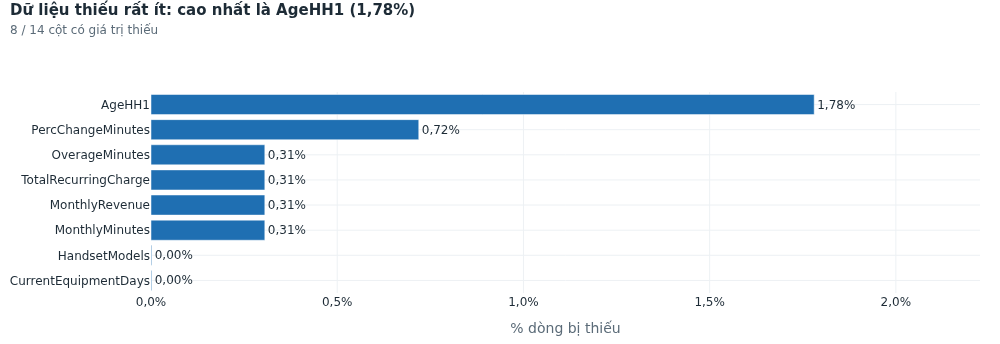

In [5]:
show("C02_du_lieu_thieu")

**Insight:** dữ liệu khá sạch. Cột thiếu nhiều nhất là `AgeHH1` (1,78%); nhóm cột usage/revenue thiếu 0,31% (156 khách, cùng một nhóm). Vì vậy giữ toàn bộ 51.047 khách, mỗi biểu đồ chỉ loại missing của chính cột đang xét.

## 4. Tổng quan churn

### C01 — Churn lớn đến đâu?

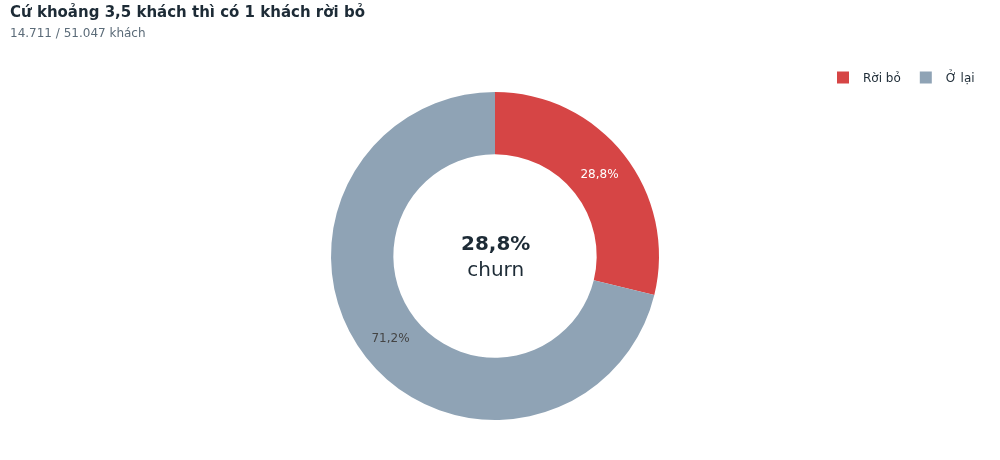

In [6]:
show("C01_ty_le_churn")

**Insight:** 14.711 / 51.047 khách rời bỏ (**28,8%**), cứ khoảng 3,5 khách thì có 1 khách đi. Doanh thu hàng tháng của nhóm đã rời bỏ khoảng **$849 nghìn**. Dữ liệu mất cân bằng vừa phải (71/29) nên mọi so sánh dùng churn rate, không dùng số tuyệt đối.

### C03 — Phân bố tuổi thiết bị khác nhau thế nào giữa hai nhóm?

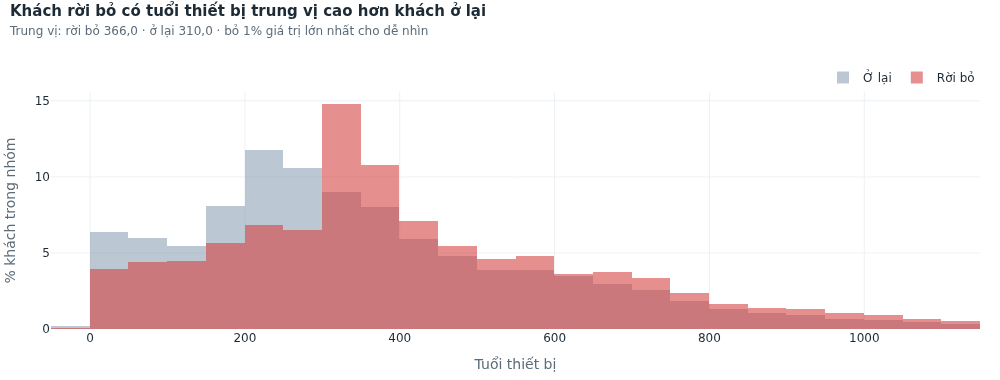

In [7]:
show("C03_phan_bo_tuoi_may")

**Insight:** trung vị tuổi máy của khách rời bỏ là **366 ngày**, của khách ở lại là **310 ngày**. Phân bố của nhóm churn lệch hẳn về phía máy cũ. Ngược lại, doanh thu trung vị gần như bằng nhau (47,5 so với 48,8 $), nên doanh thu không phân biệt được hai nhóm.

### C04 — Outlier và độ phân tán ở các biến chính?

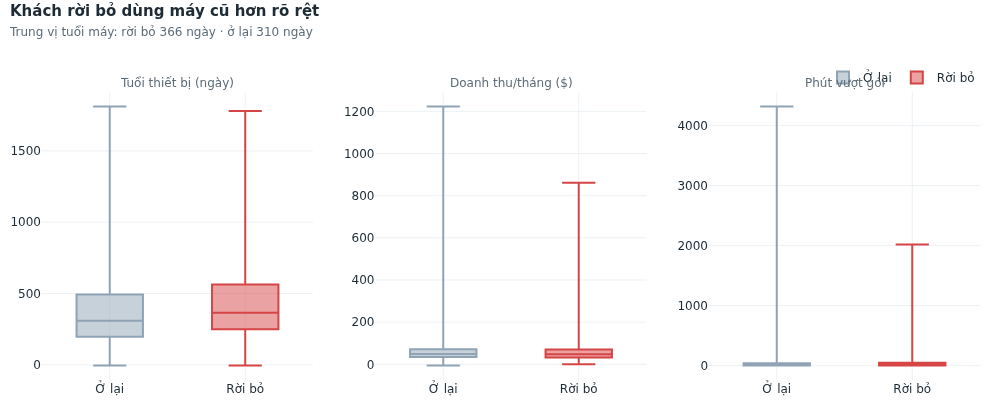

In [8]:
show("C04_box_plot")

**Insight:** cả ba biến đều lệch phải và có nhiều outlier (doanh thu > $200, vượt gói > 1.000 phút). Hộp tuổi máy của nhóm churn dịch hẳn lên trên. Outlier được giữ lại vì là khách thật, không phải lỗi.

## 5. Vòng đời và thiết bị

### C05 — Churn thay đổi thế nào theo thời gian sử dụng?

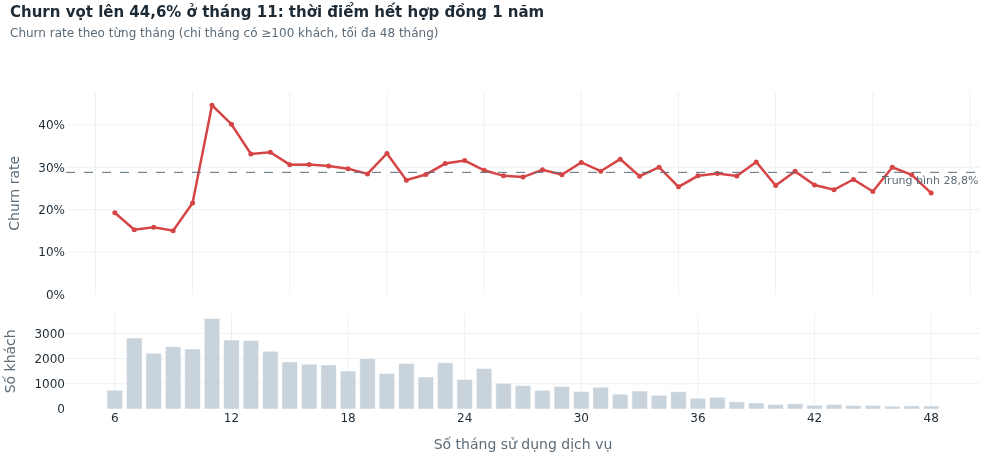

In [9]:
show("C05_vong_doi")

**Insight:** đây là phát hiện quan trọng nhất. Tháng 7–9 churn chỉ khoảng 15%, rồi **vọt lên 44,6% ở tháng 11 và 40,2% ở tháng 12**, gần gấp 3 lần. Dấu hiệu rõ của việc **hết hợp đồng 1 năm**. Sau tháng 18 churn quay về quanh mức trung bình. → Cửa sổ giữ chân là tháng 10–13, phải liên hệ **trước** tháng 11.

### C06 — Tuổi thiết bị ảnh hưởng ra sao?

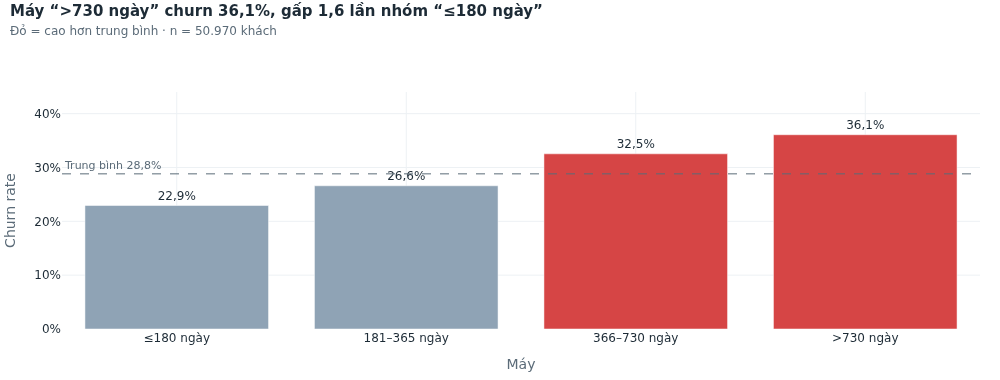

In [10]:
show("C06_tuoi_thiet_bi")

**Insight:** churn tăng đều theo tuổi máy: ≤180 ngày **22,9%** → 181–365 ngày 26,6% → 366–730 ngày 32,5% → >730 ngày **36,1%**. Đây là biến numeric tương quan mạnh nhất với churn (xem C18). → Chính sách đổi máy là đòn bẩy rõ nhất.

### C07 — Tenure và tuổi máy kết hợp thế nào?

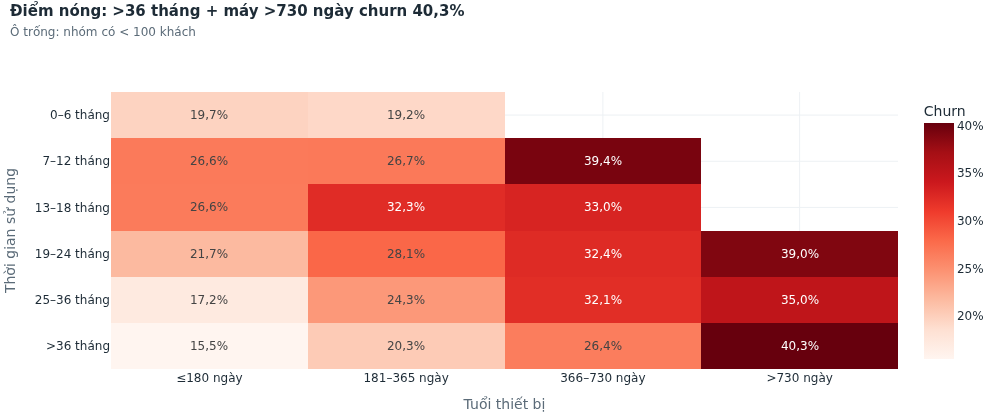

In [11]:
show("C07_heatmap_tenure_thiet_bi")

**Insight:** hai tín hiệu cộng dồn. Khách đã gắn bó lâu (>36 tháng) nhưng dùng máy >2 năm churn **40,3%**, gấp 2,6 lần khách lâu năm dùng máy mới (15,5%). Khách 7–12 tháng mà máy đã 1–2 năm tuổi (nhiều khả năng máy cũ/tân trang khi đăng ký) churn **39,4%**. Ngược lại, máy ≤180 ngày luôn churn thấp ở mọi tenure.

### C09 — Máy không hỗ trợ web hoặc máy tân trang có churn cao hơn?

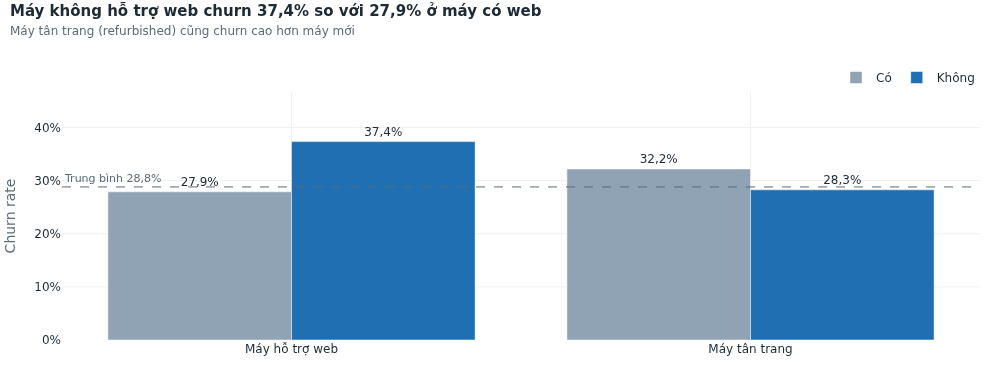

In [12]:
show("C09_dac_diem_thiet_bi")

**Insight:** máy không hỗ trợ web churn **37,4%** so với 27,9%; máy tân trang (refurbished) 32,2% so với 28,3%. Khách dùng máy đời cũ, chức năng hạn chế dễ bị đối thủ lôi kéo bằng ưu đãi máy mới.

## 6. Hành vi sử dụng dịch vụ

### C08 — Chương trình giữ chân hiện tại có hiệu quả không?

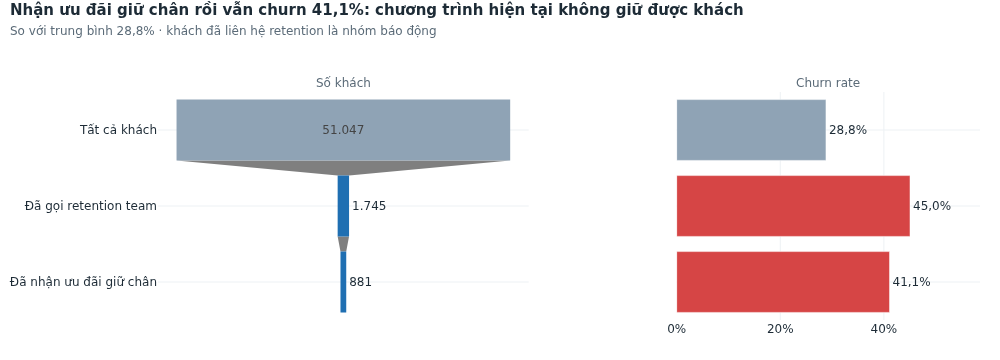

In [13]:
show("C08_retention_funnel")

**Insight:** 1.745 khách đã chủ động gọi bộ phận retention: churn **45,0%**. 881 khách đã nhận ưu đãi giữ chân nhưng vẫn churn **41,1%**, cao hơn hẳn mức trung bình 28,8%. Đây là quan hệ quan sát (khách gọi retention vốn đã muốn đi), nhưng cho thấy ưu đãi hiện tại **không đủ hấp dẫn**. → Nhóm này cần ưu tiên số 1 và ưu đãi cần được thiết kế lại.

### C10 — Gọi chăm sóc khách hàng nhiều có phải dấu hiệu bất mãn?

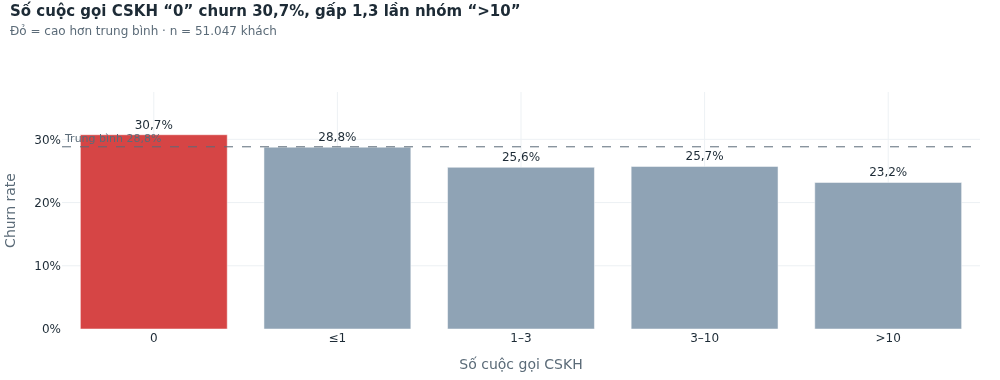

In [14]:
show("C10_goi_cskh")

**Insight:** **nghịch lý:** khách **không** gọi CSKH churn cao nhất (**30,7%**, 28.020 khách), khách gọi >10 lần/tháng chỉ 23,2%. Khách có tương tác là khách còn quan tâm dịch vụ; khách im lặng mới là khách đã "rời lòng". → Không nên chỉ chờ khiếu nại để phát hiện rủi ro.

### C11 — Chất lượng mạng (cuộc gọi rớt/bị chặn) có gây churn?

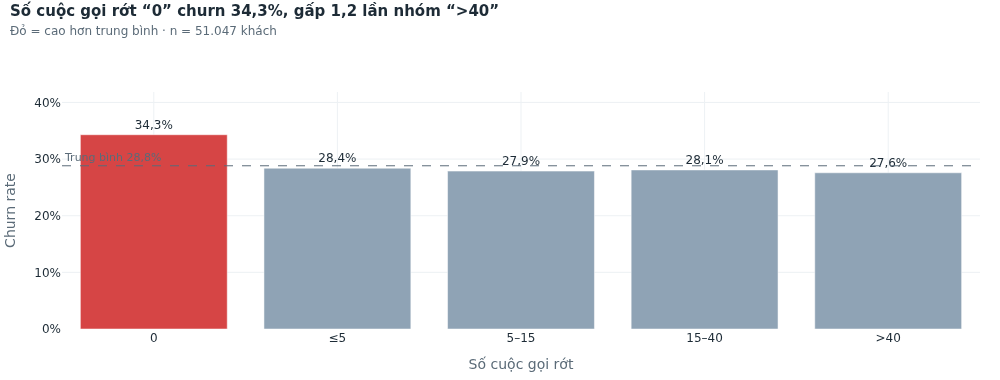

In [15]:
show("C11_cuoc_goi_rot")

**Insight:** khách **không có** cuộc gọi rớt nào lại churn cao nhất (**34,3%**). Các nhóm còn lại đều quanh 28%. Cuộc gọi rớt = 0 chủ yếu do dùng rất ít, nên đây là tín hiệu **ít sử dụng** chứ không phải mạng tốt. Dữ liệu **không** cho thấy chất lượng mạng là nguyên nhân churn chính.

### C12 — Gói cước có phù hợp với nhu cầu?

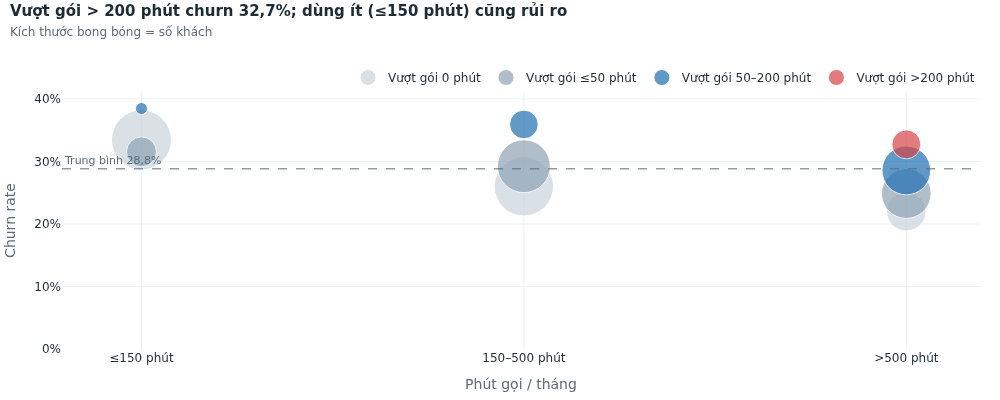

In [16]:
show("C12_goi_cuoc")

**Insight:** hai kiểu lệch gói đều rủi ro. (1) Dùng ít ≤150 phút churn 33,1%: khách ít dùng, thấy gói không đáng tiền. (2) Vượt gói >200 phút churn **32,7%**: khách bị phạt phí vượt, hóa đơn cao. Khách dùng nhiều mà không vượt gói churn thấp nhất (~22%). → Tư vấn đúng gói là cơ hội giữ chân.

## 7. Địa lý

### C13 — Vùng nào churn cao nhất?

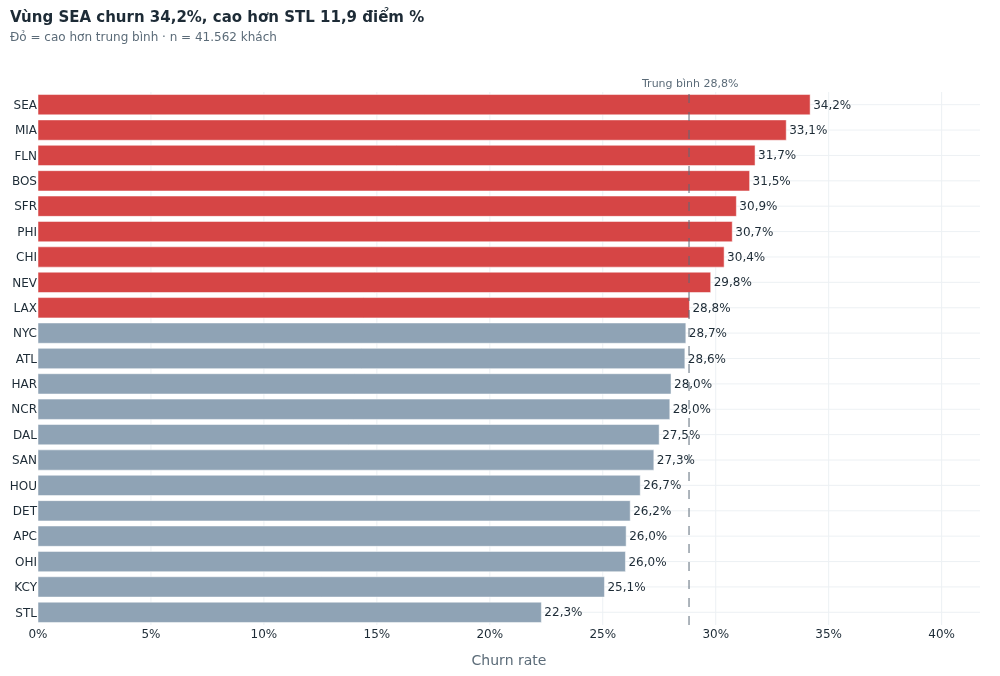

In [17]:
show("C13_vung")

**Insight:** chênh lệch theo vùng đến **11,9 điểm %**: SEA 34,2%, MIA 33,1% so với STL 22,3%, KCY 25,1% (chỉ xét vùng ≥ 800 khách). → Cần xem cạnh tranh và chất lượng dịch vụ tại SEA, MIA, FLN, BOS.

### C14 — Churner tập trung ở đâu về số lượng?

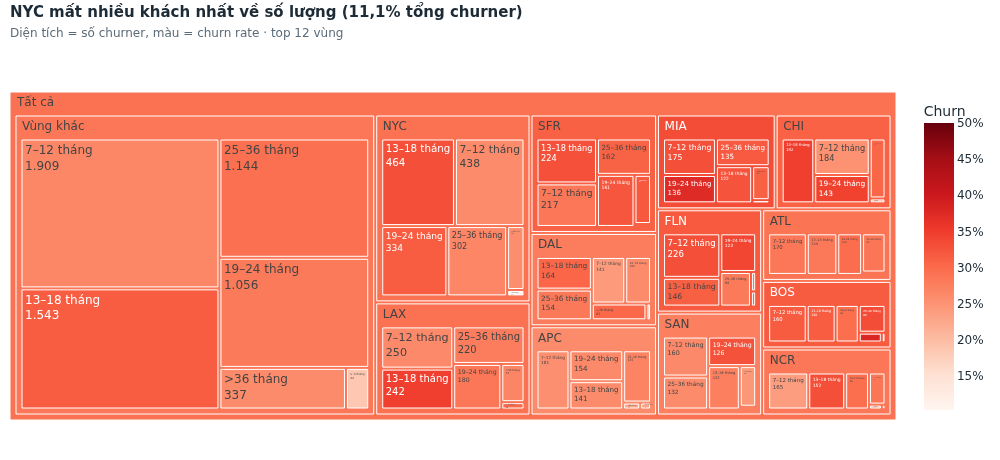

In [18]:
show("C14_treemap_vung")

**Insight:** vùng có **rate** cao chưa chắc là vùng mất **nhiều khách** nhất. NYC churn gần mức trung bình nhưng chiếm **11,1%** tổng churner vì quy mô lớn. Trong mỗi vùng, khối 7–18 tháng luôn lớn nhất, khớp với đỉnh hết hợp đồng ở C05.

### C15 — Bao nhiêu vùng chiếm 80% số khách rời bỏ?

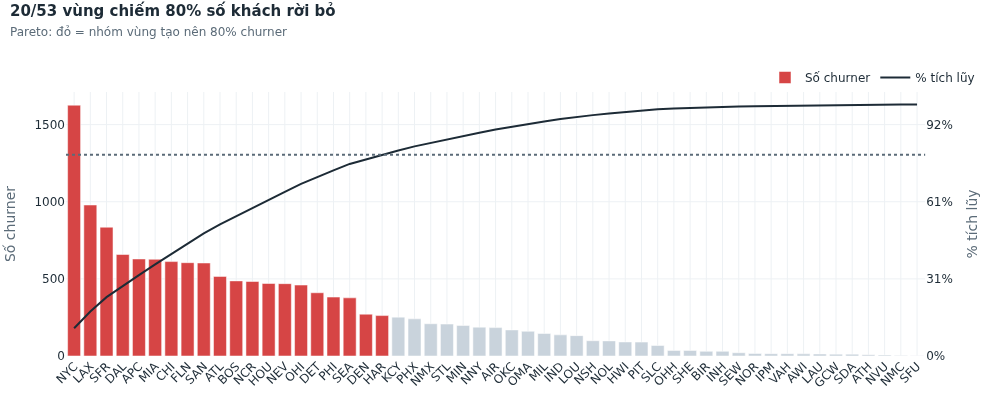

In [19]:
show("C15_pareto_vung")

**Insight:** **20/53 vùng** tạo ra 80% churner. Chiến dịch giữ chân có thể bắt đầu ở nhóm vùng này để có độ phủ cao với chi phí triển khai thấp.

## 8. Đặc điểm khách hàng

### C16 — Hạng tín dụng liên quan thế nào đến churn?

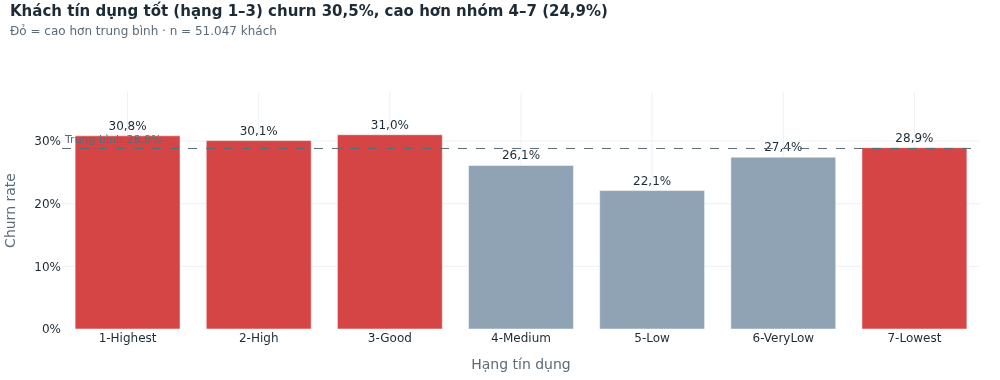

In [20]:
show("C16_tin_dung")

**Insight:** ngược với trực giác: khách tín dụng **tốt** (hạng 1–3) churn **30,5%**, cao hơn nhóm 4–7 (24,9%); thấp nhất là 5-Low (22,1%). Giả thuyết: khách tín dụng tốt dễ được đối thủ chấp nhận và mời chào, nên dễ chuyển mạng hơn.

### C17 — Thu nhập, nghề nghiệp, khu vực sống, hôn nhân có quan trọng?

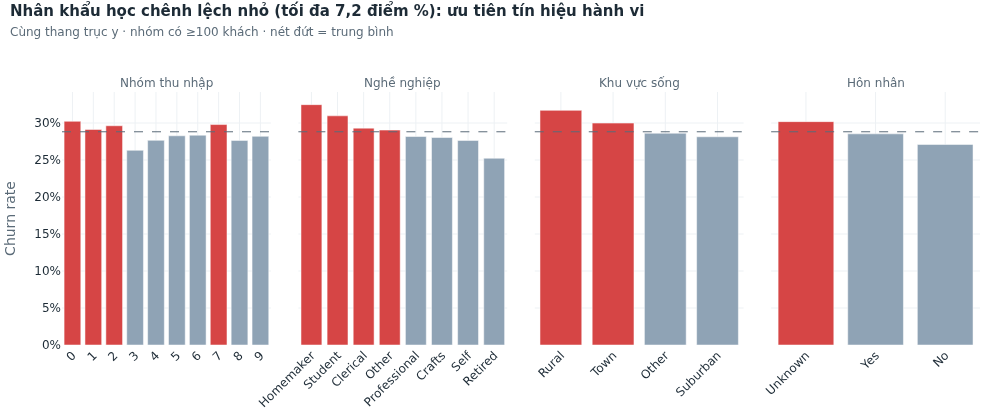

In [21]:
show("C17_nhan_khau_hoc")

**Insight:** chênh lệch nhỏ. Thu nhập và hôn nhân dao động 3–4 điểm %; nghề nghiệp tối đa 7 điểm nhưng nhóm cao nhất (Homemaker) chỉ có 157 khách. → Nhân khẩu học **không** phải cơ sở tốt để chọn khách can thiệp; nên dùng tín hiệu hành vi và thiết bị.

### C18 — Biến numeric nào tương quan với churn và với nhau?

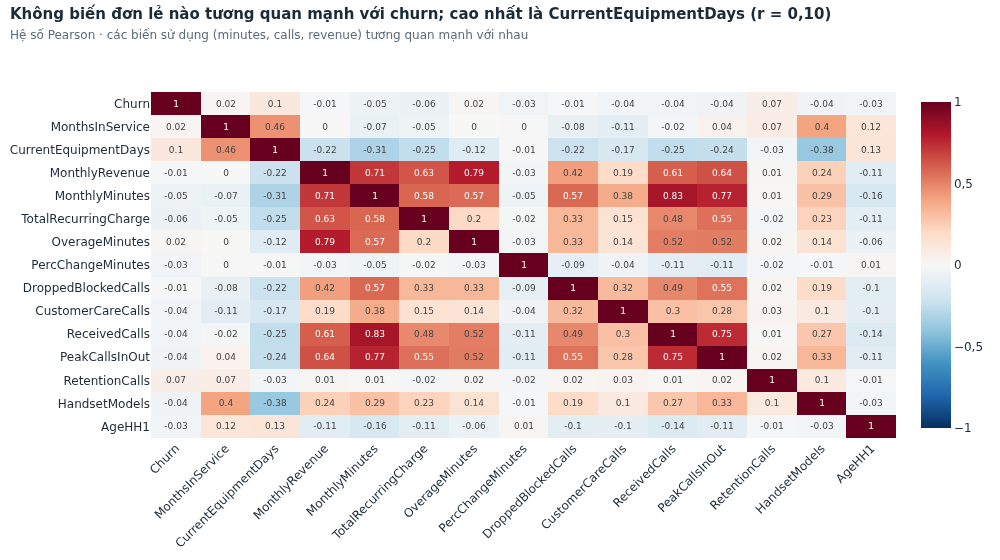

In [22]:
show("C18_tuong_quan")

**Insight:** không biến đơn lẻ nào tương quan mạnh với churn (|r| ≤ 0,10, cao nhất là tuổi máy). Churn là kết quả **kết hợp** nhiều tín hiệu yếu, nên cần phân khúc hoặc mô hình thay vì một ngưỡng đơn. Các biến sử dụng (phút gọi, số cuộc gọi, doanh thu) tương quan mạnh với nhau (r > 0,7), chọn đại diện là đủ.

## 9. Ai cần ưu tiên — mô hình rủi ro và phân khúc hành động

Điểm rủi ro lấy từ notebook 03 (CatBoost, 10 biến, dự đoán ngoài mẫu 3-fold). Ở đây chỉ **diễn giải**, không train lại.

### C19a — Điểm rủi ro có phân tầng được khách hàng?

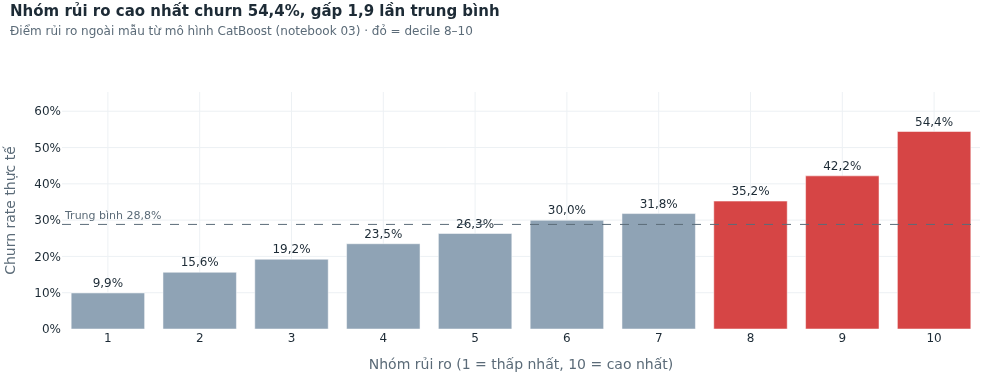

In [23]:
show("C19a_risk_decile")

**Insight:** có. Churn thực tế tăng đều từ decile 1 đến 10; decile 10 churn **54,4%**, gấp 1,9 lần trung bình. Mô hình hữu ích để **xếp hạng** nhưng không hoàn hảo (ROC-AUC ≈ 0,67).

### C19b — Với ngân sách hữu hạn, liên hệ bao nhiêu khách là đủ?

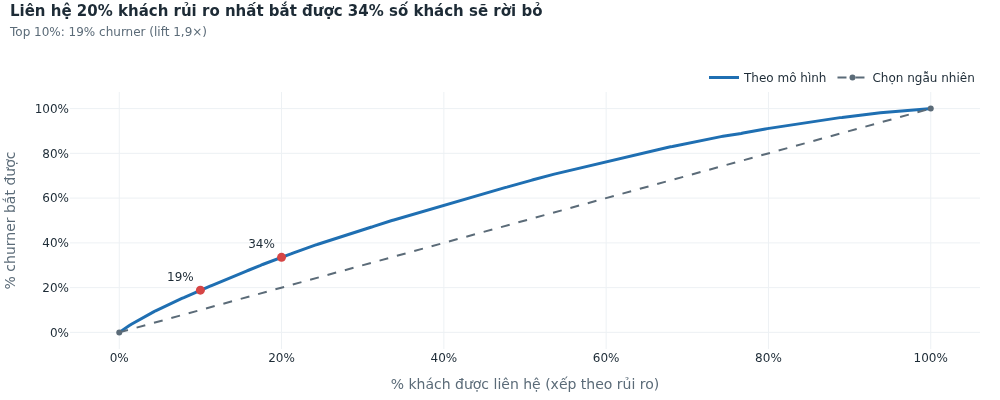

In [24]:
show("C19b_gain_curve")

**Insight:** liên hệ 10% khách rủi ro nhất bắt được **19%** số khách sẽ rời bỏ (lift 1,9×), 20% bắt được **34%**. So với chọn ngẫu nhiên, cùng ngân sách nhắm trúng gần gấp đôi.

**Rule phân khúc hành động** (`ActionSegment`, xét theo thứ tự, khách khớp rule đầu tiên sẽ thuộc nhóm đó):

| # | Phân khúc | Điều kiện | Căn cứ |
|---|---|---|---|
| 1 | Đã báo động | Đã gọi retention team | C08 |
| 2 | Hết hợp đồng | Tháng sử dụng 10–13 | C05 |
| 3 | Máy cũ | Máy > 730 ngày, hoặc ≥ 365 ngày và không hỗ trợ web | C06, C07, C09 |
| 4 | Rủi ro cao (mô hình) | Còn lại, risk decile 8–10 | C19 |
| 5 | Ổn định | Còn lại | |

Trong bản nháp có thử nhóm "Sai gói" (vượt gói > 100 phút) và "Im lặng" (không gọi CSKH và < 150 phút). Sau khi đã tách 3 nhóm đầu,
hai nhóm này churn **thấp hơn** trung bình (24,3% và 25,1%) nên đã bỏ: tín hiệu của chúng đã nằm trong các nhóm trên.

In [25]:
seg = c.segment_summary(df)
seg.assign(rate=seg.rate.map(c.fmt_pct), revenue_at_risk=seg.revenue_at_risk.map(c.fmt_money),
           avg_revenue=seg.avg_revenue.round(1)).drop(columns="revenue")

,ActionSegment,n,churners,avg_revenue,rate,revenue_at_risk
0,Đã báo động,1745,786,61.6,"45,0%","$48,1 nghìn"
1,Hết hợp đồng,11161,3960,58.1,"35,5%","$230,1 nghìn"
2,Máy cũ,6837,2430,43.6,"35,5%","$104,8 nghìn"
3,Rủi ro cao (mô hình),4879,2067,65.7,"42,4%","$135,0 nghìn"
4,Ổn định,26425,5468,61.6,"20,7%","$336,3 nghìn"


### C20 — Phân khúc nào cần ưu tiên, theo rủi ro và giá trị?

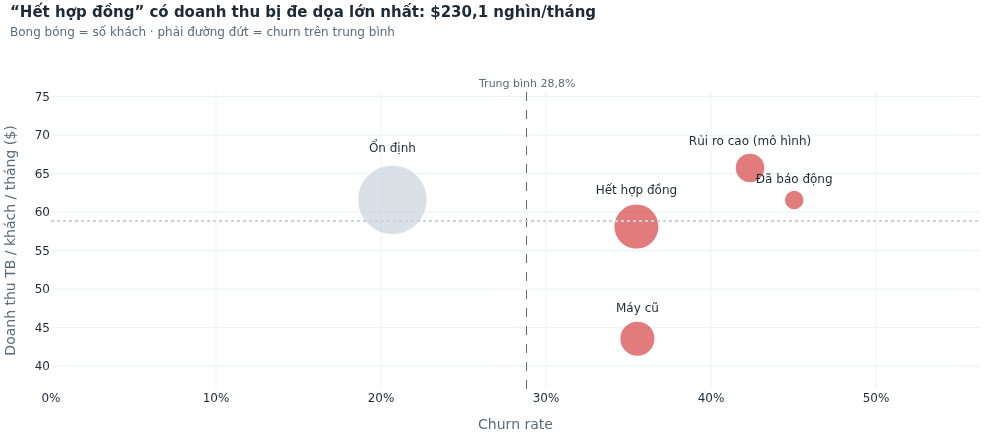

In [26]:
show("C20_phan_khuc")

**Insight:** 4 nhóm cần can thiệp gồm **24.622 khách** (48% tập khách), tất cả churn trên mức trung bình (35–45%), trong khi nhóm Ổn định chỉ 20,7%. **Hết hợp đồng** có doanh thu bị đe dọa lớn nhất (~$230 nghìn/tháng). **Rủi ro cao (mô hình)** có doanh thu/khách cao nhất ($65,7). **Máy cũ** có doanh thu/khách thấp ($43,6), nên ưu đãi máy phải tiết chế chi phí.

## 10. Đề xuất chính sách giữ chân

| Ưu tiên | Phân khúc | Chính sách đề xuất | KPI đo hiệu quả |
|---|---|---|---|
| 1 | Đã báo động (1.745 khách, churn 45%) | Thiết kế lại gói ưu đãi giữ chân; chuyển chuyên viên cấp cao xử lý trong 24h; đo lý do rời bỏ khi khách gọi | Churn 60 ngày của nhóm; tỷ lệ chấp nhận ưu đãi |
| 2 | Hết hợp đồng (11.161 khách, churn 35,5%) | Gọi chăm sóc chủ động từ **tháng 10**; ưu đãi gia hạn 12 tháng (giảm cước hoặc data) trước tháng 11 | Tỷ lệ gia hạn; churn tháng 11–13 |
| 3 | Máy cũ (6.837 khách, churn 35,5%) | Chương trình đổi máy smartphone trả góp/trợ giá gắn cam kết 12 tháng; ưu tiên khách máy không hỗ trợ web | % nhận đổi máy; churn 90 ngày; chi phí trợ giá/khách giữ được |
| 4 | Rủi ro cao theo mô hình (4.879 khách, churn 42,4%) | Khảo sát hài lòng + tư vấn gói phù hợp (chống vượt gói/gói thừa); giá trị cao nên ưu đãi cá nhân hóa | Churn 90 ngày; doanh thu giữ được |
| — | Ổn định | Duy trì, chương trình khách hàng thân thiết | Không đổi |

Hỗ trợ theo vùng: bắt đầu triển khai ở 20 vùng chiếm 80% churner (C15), ưu tiên SEA, MIA (rate cao) và NYC, LAX (số lượng lớn).

*Đây là đề xuất dựa trên quan hệ quan sát. Trước khi triển khai rộng cần A/B test (nhóm thử và nhóm đối chứng) để đo mức giảm churn thực tế.*

## 11. Tổng kết — 7 insight chính

1. **Churn 28,8%** (14.711/51.047 khách), doanh thu tháng của nhóm đã rời bỏ khoảng $849 nghìn.
2. **Đỉnh hết hợp đồng:** churn vọt từ ~15% (tháng 7–9) lên **44,6%** ở tháng 11, nên cửa sổ giữ chân là tháng 10–13.
3. **Thiết bị là đòn bẩy rõ nhất:** máy > 2 năm churn 36,1%, gấp 1,6 lần máy mới; máy không hỗ trợ web 37,4%.
4. **Chương trình giữ chân hiện tại kém hiệu quả:** khách đã nhận ưu đãi vẫn churn 41,1%.
5. **Khách im lặng nguy hiểm hơn khách phàn nàn:** không gọi CSKH churn 30,7%, không có cuộc gọi rớt (ít dùng) churn 34,3%.
6. **Địa lý và tín dụng:** chênh lệch 12 điểm % giữa các vùng; khách tín dụng tốt churn cao hơn. Nhân khẩu học khác gần như không phân biệt.
7. **Ưu tiên 4 phân khúc** (24.622 khách, churn 35–45%); mô hình giúp nhắm 20% khách bắt được 34% churner.

**Giới hạn:** dữ liệu là một snapshot, các quan hệ là tương quan, không chứng minh nhân quả. `MonthlyRevenue` là doanh thu hiện tại, không phải lợi nhuận hay CLV.